# 04 — CheXpert Plus: Evaluation (RQ1 + RQ3)
RQ1: Classification metrics (F1, Sensitivity, Specificity, AUROC)
RQ3: Calibration (ECE, Brier Score, Reliability Diagram)
Note: RQ2 (report quality) skipped — no section_impression in benchmark metadata.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(os.getcwd()).parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src2.utils import load_config, load_results
from src2.metrics import (
    compute_classification_metrics, add_ci_to_metrics,
    compute_ece, compute_brier, compute_reliability_data,
)

CFG         = load_config(PROJECT_ROOT / 'configs2' / 'server.yaml')
OUTPUT_ROOT = Path(CFG['paths']['output_root'])
DATASET_OUT = OUTPUT_ROOT / 'chexpert_plus'
FIG_DIR     = DATASET_OUT / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

JSONL_MEDGEMMA  = OUTPUT_ROOT / CFG['outputs']['chexpert_plus']['medgemma']
JSONL_MEDSIGLIP = OUTPUT_ROOT / CFG['outputs']['chexpert_plus']['medsiglip']

print('MedGemma JSONL :', JSONL_MEDGEMMA, '—', 'exists' if JSONL_MEDGEMMA.exists() else 'MISSING')
print('MedSigLIP JSONL:', JSONL_MEDSIGLIP, '—', 'exists' if JSONL_MEDSIGLIP.exists() else 'MISSING')

MedGemma JSONL : /data/arta/thoraxai_research/2_srg/hasil_penelitian_2/outputs/chexpert_plus/medgemma.jsonl — exists
MedSigLIP JSONL: /data/arta/thoraxai_research/2_srg/hasil_penelitian_2/outputs/chexpert_plus/medsiglip.jsonl — exists


In [2]:
def load_df(jsonl_path):
    records = load_results(jsonl_path)
    df = pd.DataFrame(records)
    print(f'{jsonl_path.name}: {len(df)} records, parse_success={df.parse_success.mean():.3f}')
    return df

df_gem = load_df(JSONL_MEDGEMMA)
df_sip = load_df(JSONL_MEDSIGLIP)

medgemma.jsonl: 1050 records, parse_success=1.000
medsiglip.jsonl: 1050 records, parse_success=1.000


In [3]:
# ── RQ1: Classification ────────────────────────────────────────────────────────

def eval_classification(df, name):
    y_true  = df['label_gt'].values
    y_pred  = df['diagnosis'].values
    y_score = df['confidence_explicit'].values.astype(float)
    m = compute_classification_metrics(y_true, y_pred, y_score)
    m = add_ci_to_metrics(m, y_true, y_pred)
    m['model'] = name
    m['parse_rate'] = float(df['parse_success'].mean())
    return m

results_rq1 = {
    'MedGemma-1.5-4B': eval_classification(df_gem, 'MedGemma-1.5-4B'),
    'MedSigLIP':        eval_classification(df_sip, 'MedSigLIP'),
}

for name, m in results_rq1.items():
    print(f"\n{name}")
    print(f"  F1={m['f1']:.4f} [{m['f1_ci'][0]:.4f}-{m['f1_ci'][1]:.4f}]")
    print(f"  Sens={m['sensitivity']:.4f}  Spec={m['specificity']:.4f}  AUROC={m['auroc']}")
    print(f"  TP={m['tp']}  FP={m['fp']}  FN={m['fn']}  TN={m['tn']}")

with open(DATASET_OUT / 'rq1_classification_results.json', 'w') as f:
    json.dump(results_rq1, f, indent=2)
print('\nSaved rq1_classification_results.json')


MedGemma-1.5-4B
  F1=0.3227 [0.2751-0.3701]
  Sens=0.2020  Spec=0.9545  AUROC=0.4797
  TP=101  FP=25  FN=399  TN=525

MedSigLIP
  F1=0.3475 [0.3017-0.3924]
  Sens=0.2460  Spec=0.8455  AUROC=0.6047
  TP=123  FP=85  FN=377  TN=465

Saved rq1_classification_results.json


In [4]:
# ── RQ3: Calibration ──────────────────────────────────────────────────────────

def eval_calibration(df, name):
    y_true = df['label_gt'].values
    y_conf = df['confidence_explicit'].values.astype(float)/10
    ece    = compute_ece(y_true, y_conf)
    brier  = compute_brier(y_true, y_conf)
    # Logit-based confidence (MedGemma only)
    ece_logit = None
    if 'confidence_logit' in df.columns:
        y_logit = df['confidence_logit'].values.astype(float)
        if not np.all(np.isnan(y_logit)):
            ece_logit = compute_ece(y_true, y_logit)
    return {'ece_explicit': round(ece, 4), 'brier': round(brier, 4),
            'ece_logit': round(ece_logit, 4) if ece_logit is not None else None,
            'n_valid': int(len(df))}

results_rq3 = {
    'MedGemma-1.5-4B': eval_calibration(df_gem, 'MedGemma-1.5-4B'),
    'MedSigLIP':        eval_calibration(df_sip, 'MedSigLIP'),
}

for name, m in results_rq3.items():
    print(f"{name}: ECE={m['ece_explicit']}  Brier={m['brier']}  ECE_logit={m['ece_logit']}")

with open(DATASET_OUT / 'rq3_calibration_results.json', 'w') as f:
    json.dump(results_rq3, f, indent=2)
print('Saved rq3_calibration_results.json')

MedGemma-1.5-4B: ECE=0.4153  Brier=0.4247  ECE_logit=0.456
MedSigLIP: ECE=0.4434  Brier=0.4431  ECE_logit=None
Saved rq3_calibration_results.json


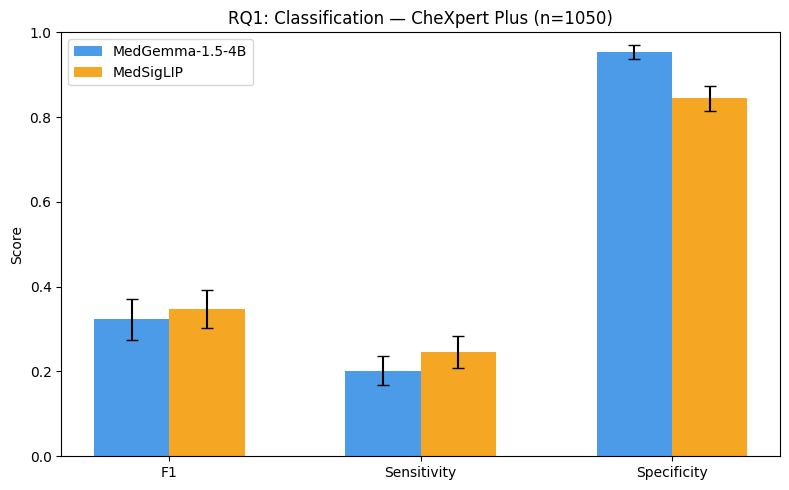

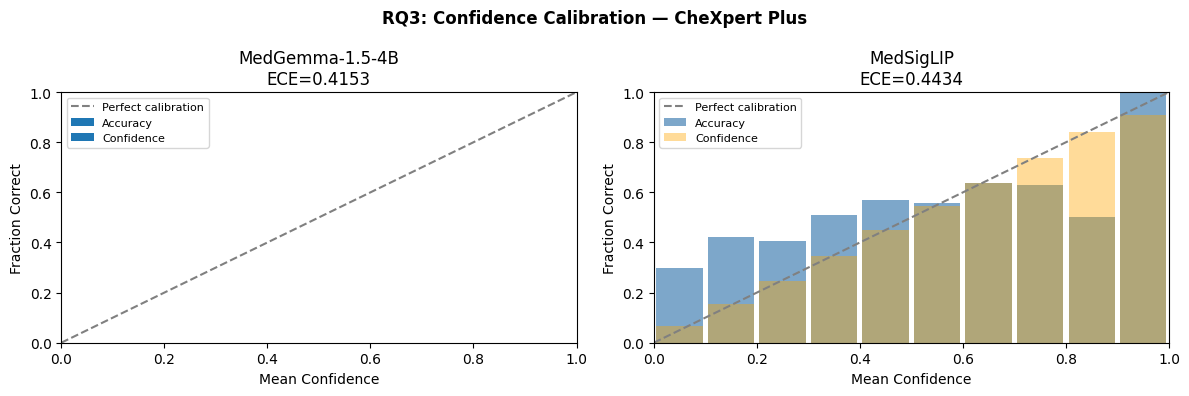

Figures saved to /data/arta/thoraxai_research/2_srg/hasil_penelitian_2/outputs/chexpert_plus/figures


In [5]:
# ── Figures ────────────────────────────────────────────────────────────────────

# RQ1 bar chart
models    = ['MedGemma-1.5-4B', 'MedSigLIP']
colors    = ['#4C9BE8', '#F5A623']
metrics_k = ['f1', 'sensitivity', 'specificity']
labels_k  = ['F1', 'Sensitivity', 'Specificity']
x = np.arange(len(metrics_k))
width = 0.3

fig, ax = plt.subplots(figsize=(8, 5))
for i, (name, color) in enumerate(zip(models, colors)):
    m = results_rq1[name]
    vals  = [m[k] for k in metrics_k]
    lows  = [m[k] - m[f'{k}_ci'][0] if m.get(f'{k}_ci') and m[f'{k}_ci'][0] else 0 for k in metrics_k]
    highs = [m[f'{k}_ci'][1] - m[k] if m.get(f'{k}_ci') and m[f'{k}_ci'][1] else 0 for k in metrics_k]
    ax.bar(x + i*width - width/2, vals, width, label=name, color=color,
           yerr=[lows, highs], capsize=4, error_kw={'linewidth':1.5})

ax.set_xticks(x)
ax.set_xticklabels(labels_k)
ax.set_ylim(0, 1.0)
ax.set_ylabel('Score')
ax.set_title('RQ1: Classification — CheXpert Plus (n=1050)')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'rq1_classification.png', dpi=150)
plt.show()

# RQ3 reliability diagrams
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('RQ3: Confidence Calibration — CheXpert Plus', fontweight='bold')

for ax, (name, df_m) in zip(axes, [('MedGemma-1.5-4B', df_gem), ('MedSigLIP', df_sip)]):
    y_true = df_m['label_gt'].values
    y_conf = df_m['confidence_explicit'].values.astype(float)
    rel    = compute_reliability_data(y_true, y_conf)
    ece_v  = results_rq3[name]['ece_explicit']
    valid  = rel.dropna()
    ax.bar(valid['bin_center'], valid['mean_acc'], width=0.09, alpha=0.7, label='Accuracy', color='steelblue')
    ax.bar(valid['bin_center'], valid['mean_conf'], width=0.09, alpha=0.4, label='Confidence', color='orange')
    ax.plot([0,1],[0,1],'--', color='gray', label='Perfect calibration')
    ax.set_title(f'{name}\nECE={ece_v:.4f}')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('Mean Confidence')
    ax.set_ylabel('Fraction Correct')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / 'rq3_reliability_diagrams.png', dpi=150)
plt.show()

print('Figures saved to', FIG_DIR)